# Boston Housing | Linear Regression Analysis

**Codveda Technologies — Machine Learning Internship**  
**Level 1 | Task 2: Linear Regression**

## Project Overview

This project explores linear regression using the historical Boston Housing dataset. The objective is to understand the relationship between housing characteristics and median home values, build an interpretable regression model, and evaluate its predictive performance.

## Objectives

- Inspect and prepare the dataset for regression analysis.
- Explore feature distributions and relationships with the target.
- Build a linear regression model using scikit-learn.
- Interpret model coefficients and predictions.
- Evaluate performance using Mean Squared Error (MSE) and R².
- Assess model limitations and document the findings.

## Dataset

**Source:** Boston Housing dataset provided by Codveda Technologies  
**Target:** MEDV — Median owner-occupied home value (in $1,000s)  
**Tools:** Python, pandas, scikit-learn, Matplotlib, Seaborn

The dataset is historical and includes sensitive socioeconomic and race-derived attributes. The analysis is intended for educational purposes, not real-world property valuation.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from joblib import dump, load

RANDOM_STATE = 42
TEST_SIZE = 0.20


## Data Loading & Inspection

Load the dataset, verify its structure, and examine missing values, duplicates, and summary statistics.


In [2]:
column_names = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

DATA_PATH = None

if DATA_PATH is None:
    search_roots = [Path("/kaggle/input"), Path(".")]

    matching_files = sorted({
        path.resolve()
        for root in search_roots if root.exists()
        for path in root.rglob("*.csv")
        if "house" in path.name.lower()
        and "prediction" in path.name.lower()
    })

    if len(matching_files) != 1:
        raise FileNotFoundError(
            f"Found {len(matching_files)} matching files: {matching_files}. "
            "Set DATA_PATH to the exact dataset path."
        )

    DATA_PATH = matching_files[0]
else:
    DATA_PATH = Path(DATA_PATH)
    
df = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)

print(f"Dataset Source: {DATA_PATH}")
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")

display(df.head())


Dataset Source: /kaggle/input/datasets/nebalelshobary/house-prediction-dataset/4) house Prediction Data Set.csv
Dataset Shape: 506 rows × 14 columns


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [4]:
missing_counts = df.isna().sum()
duplicate_count = df.duplicated().sum()

print(f"Total Missing Values: {missing_counts.sum()}")
print(f"Columns with Missing Values: {(missing_counts > 0).sum()}")
print(f"Exact Duplicate Rows: {duplicate_count}")

if missing_counts.sum() > 0:
    display(
        missing_counts[missing_counts > 0]
        .rename("Missing Count")
        .to_frame()
    )

Total Missing Values: 0
Columns with Missing Values: 0
Exact Duplicate Rows: 0


In [5]:
display(df.describe().round(2))

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00
mean,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65,22.53
std,8.60,23.32,6.86,0.25,0.12,0.70,28.15,2.11,8.71,168.54,2.16,91.29,7.14,9.20
min,0.01,0.00,0.46,0.00,0.38,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
25%,0.08,0.00,5.19,0.00,0.45,5.89,45.02,2.10,4.00,279.00,17.40,375.38,6.95,17.02
50%,0.26,0.00,9.69,0.00,0.54,6.21,77.50,3.21,5.00,330.00,19.05,391.44,11.36,21.20
75%,3.68,12.50,18.10,0.00,0.62,6.62,94.07,5.19,24.00,666.00,20.20,396.22,16.96,25.00
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


## Feature Selection & Exploratory Analysis

Prepare the predictors and target, exclude the race-derived feature B, and explore relationships using the training data.

In [6]:
target_column = "MEDV"

X = df.drop(columns=[target_column, "B"])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print(f"Training Set: {X_train.shape[0]} samples")
print(f"Test Set: {X_test.shape[0]} samples")
print(f"Available Features: {X_train.shape[1]}")

Training Set: 404 samples
Test Set: 102 samples
Available Features: 12


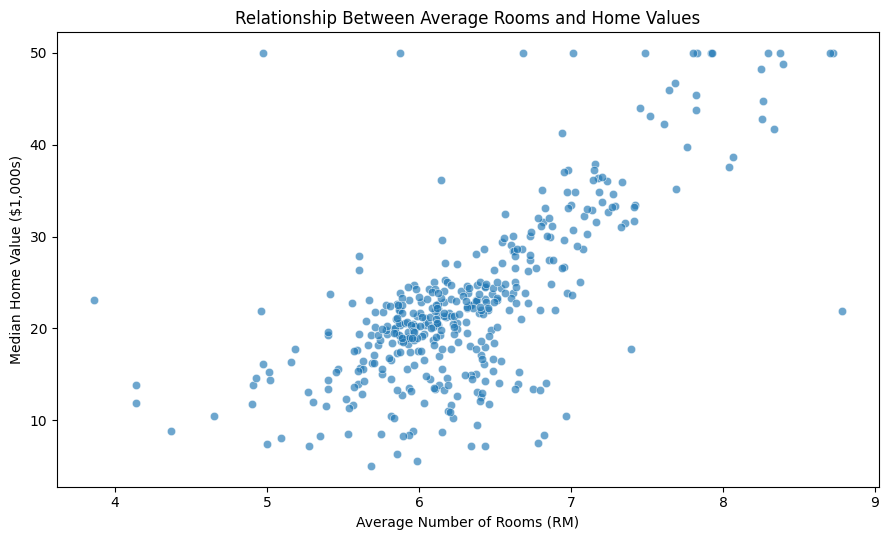

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.scatterplot(
    x=X_train["RM"],
    y=y_train,
    alpha=0.65,
    ax=ax
)

ax.set(
    title="Relationship Between Average Rooms and Home Values",
    xlabel="Average Number of Rooms (RM)",
    ylabel="Median Home Value ($1,000s)"
)

plt.tight_layout()
plt.show()


,Feature,Correlation with MEDV
0,LSTAT,-0.7364
1,RM,0.7107
2,PTRATIO,-0.4912
3,INDUS,-0.4705
4,TAX,-0.4598
5,NOX,-0.4158
6,RAD,-0.3875
7,CRIM,-0.3801
8,AGE,-0.3402
9,ZN,0.3095


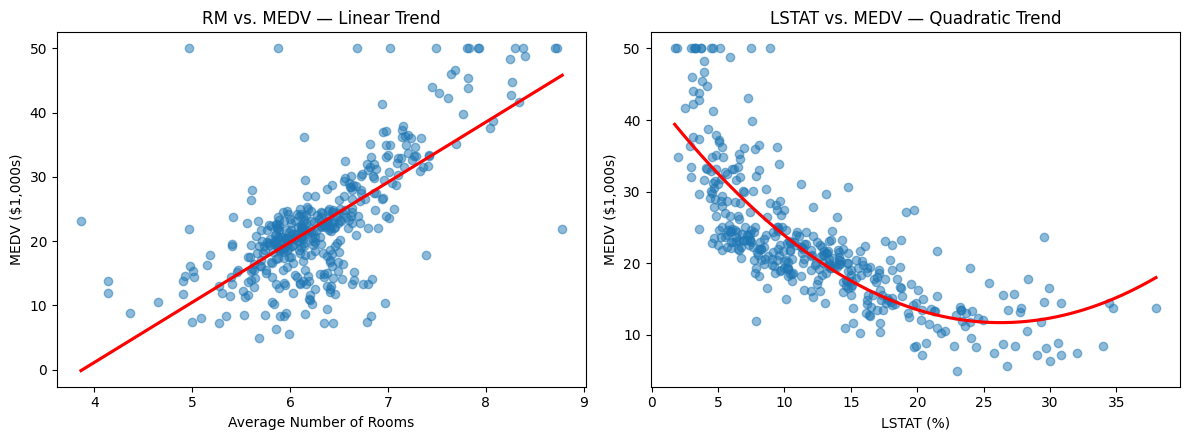

In [8]:
feature_correlations = X_train.corrwith(y_train).sort_values(
    key=lambda values: values.abs(),
    ascending=False
)

correlation_table = pd.DataFrame({
    "Feature": feature_correlations.index,
    "Correlation with MEDV": feature_correlations.values
})

display(correlation_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.regplot(
    x=X_train["RM"],
    y=y_train,
    ci=None,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[0]
)

axes[0].set(
    title="RM vs. MEDV — Linear Trend",
    xlabel="Average Number of Rooms",
    ylabel="MEDV ($1,000s)"
)

sns.regplot(
    x=X_train["LSTAT"],
    y=y_train,
    order=2,
    ci=None,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"},
    ax=axes[1]
)

axes[1].set(
    title="LSTAT vs. MEDV — Quadratic Trend",
    xlabel="LSTAT (%)",
    ylabel="MEDV ($1,000s)"
)

plt.tight_layout()
plt.show()


### EDA Findings & Feature Selection

The training-data analysis identified two strong relationships with median home values:

- **LSTAT (r = -0.7364):** The strongest negative linear correlation with MEDV. Its scatter plot suggests a nonlinear decreasing relationship.
- **RM (r = +0.7107):** The strongest positive linear correlation with MEDV. Its approximately increasing trend supports using RM as the Simple Linear Regression baseline.

Additional predictors, including PTRATIO and INDUS, showed moderate negative correlations with MEDV.

These findings motivated the use of RM and LSTAT for second-degree polynomial feature engineering. The nonlinear model was subsequently evaluated using cross-validation rather than selected solely from visual patterns.

The quadratic curve for LSTAT turns upward at higher values, so its shape should not be interpreted as evidence that increasing LSTAT raises home values. Correlation and fitted trends describe associations, not causation.


## Simple Linear Regression — Baseline

Establish an interpretable baseline using average room count (RM) as the sole predictor.

In [9]:
simple_model = LinearRegression()

simple_model.fit(X_train[["RM"]], y_train)

intercept = simple_model.intercept_
coefficient = simple_model.coef_[0]

print(f"Intercept: {intercept:.4f}")
print(f"RM Coefficient: {coefficient:.4f}")
print(f"Regression Equation: MEDV = {intercept:.4f} + ({coefficient:.4f} × RM)")


Intercept: -36.2463
RM Coefficient: 9.3483
Regression Equation: MEDV = -36.2463 + (9.3483 × RM)


In [10]:
train_predictions = simple_model.predict(X_train[["RM"]])

train_mse = mean_squared_error(y_train, train_predictions)
train_r2 = r2_score(y_train, train_predictions)

print(f"Training MSE: {train_mse:.4f}")
print(f"Training R²: {train_r2:.4f}")

Training MSE: 42.9966
Training R²: 0.5051


### Baseline Model Findings

The simple linear regression model was trained using `RM` as the sole predictor of median home values.

**Fitted Regression Equation:**

\[
\widehat{MEDV} = -36.2463 + 9.3483 \times RM
\]

**Coefficient Interpretation**

The positive coefficient (9.3483) indicates that a one-unit increase in average room count is associated with an approximately $9,348 increase in predicted median home value.

The negative intercept has no practical interpretation at zero rooms, which falls outside the observed data range.

**Training Performance**

| Metric | Value |
|---|---:|
| MSE | 42.9966 |
| R² | 0.5051 |
| RMSE (approx.) | 6.56 ($1,000s) |

The model explains approximately 50.5% of the variation in training-set home values. However, these in-sample results do not establish how well the model generalizes to unseen data.

Cross-validation will be used to assess model stability before the final test-set evaluation.


## Cross-Validation & Multiple Linear Regression

Evaluate model generalization with 5-fold cross-validation and compare the single-feature baseline with a multiple-feature regression model.

In [11]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_scores = cross_validate(
    simple_model,
    X_train[["RM"]],
    y_train,
    cv=cv,
    scoring={
        "MSE": "neg_mean_squared_error",
        "R2": "r2"
    }
)

cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MSE": -cv_scores["test_MSE"],
    "R2": cv_scores["test_R2"]
})

display(cv_results.round(4))

print(f"Mean CV MSE: {cv_results['MSE'].mean():.4f}")
print(f"Mean CV R²: {cv_results['R2'].mean():.4f}")
print(f"CV R² Std: {cv_results['R2'].std():.4f}")


,Fold,MSE,R2
0,1,47.3251,0.3344
1,2,35.6486,0.6370
2,3,56.5101,0.3639
3,4,38.5731,0.6393
4,5,38.3354,0.4215


Mean CV MSE: 43.2784
Mean CV R²: 0.4792
CV R² Std: 0.1484


In [12]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

multiple_cv_scores = cross_validate(
    multiple_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MSE": "neg_mean_squared_error",
        "R2": "r2"
    }
)

multiple_cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MSE": -multiple_cv_scores["test_MSE"],
    "R2": multiple_cv_scores["test_R2"]
})

comparison = pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "Mean CV MSE": [
        cv_results["MSE"].mean(),
        multiple_cv_results["MSE"].mean()
    ],
    "Mean CV R²": [
        cv_results["R2"].mean(),
        multiple_cv_results["R2"].mean()
    ],
    "CV R² Std": [
        cv_results["R2"].std(),
        multiple_cv_results["R2"].std()
    ]
})

display(comparison.round(4))


,Model,Mean CV MSE,Mean CV R²,CV R² Std
0,Simple Linear Regression,43.2784,0.4792,0.1484
1,Multiple Linear Regression,25.3022,0.7069,0.0813


In [13]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": multiple_model.coef_
})

print(f"Model Intercept: {multiple_model.intercept_:.4f}")

display(coefficients.round(4))


Model Intercept: 36.9705


,Feature,Coefficient
0,CRIM,-0.1272
1,ZN,0.0308
2,INDUS,0.0252
3,CHAS,3.0495
4,NOX,-18.1832
5,RM,4.2401
6,AGE,-0.0036
7,DIS,-1.4655
8,RAD,0.2400
9,TAX,-0.0113


In [14]:
rad_tax_correlation = X_train[["RAD", "TAX"]].corr().loc["RAD", "TAX"]

vif_results = []

for feature in X_train.columns:
    other_features = X_train.drop(columns=[feature])

    feature_model = LinearRegression()
    feature_model.fit(other_features, X_train[feature])

    feature_r2 = feature_model.score(other_features, X_train[feature])
    vif = 1 / (1 - feature_r2) if feature_r2 < 1 else float("inf")

    vif_results.append({
        "Feature": feature,
        "VIF": vif
    })

vif_table = pd.DataFrame(vif_results).sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print(f"RAD–TAX Correlation: {rad_tax_correlation:.4f}")

display(vif_table.round(2))


RAD–TAX Correlation: 0.9125


,Feature,VIF
0,TAX,8.93
1,RAD,7.62
2,NOX,4.46
3,DIS,4.17
4,INDUS,3.87
5,AGE,2.98
6,LSTAT,2.77
7,ZN,2.47
8,RM,1.93
9,PTRATIO,1.85


### Multicollinearity Findings

The training-data diagnostics revealed substantial multicollinearity between selected predictors.

- **RAD and TAX:** A strong positive correlation of 0.9125 indicates considerable overlap between these variables.
- **TAX (VIF = 8.93)** and **RAD (VIF = 7.62):** Both exceed the commonly used VIF threshold of 5, suggesting potentially unstable individual coefficient estimates.
- **NOX (VIF = 4.46)** and **DIS (VIF = 4.17):** These features also show notable relationships with other predictors.
- **RM (VIF = 1.93)** and **LSTAT (VIF = 2.77):** These variables exhibit comparatively lower multicollinearity.

**Implications**

Multicollinearity can increase the uncertainty and instability of individual regression coefficients, making their interpretation more difficult.

It does not necessarily prevent a model from making useful predictions.

The original predictors were retained to preserve the regression comparison. Ridge regularization was explored as an extension that can help stabilize coefficients in the presence of correlated predictors.

These diagnostics reinforce the importance of interpreting regression coefficients as conditional associations rather than causal effects.


### Interpreting Multiple Linear Regression Coefficients

The Multiple Linear Regression model was trained using 12 unscaled input features, excluding the race-derived feature `B`.

Each coefficient represents the estimated change in `MEDV` (measured in thousands of historical US dollars) for a one-unit increase in that feature, holding the other predictors constant.

**Key Coefficient Interpretations**

- **RM (+4.2401):** One additional average room is associated with an estimated increase of 4.2401 in MEDV, equivalent to approximately $4,240 in the dataset's historical monetary units.
- **LSTAT (−0.5378):** A one-percentage-point increase in LSTAT is associated with an estimated decrease of approximately 0.5378 in MEDV.
- **PTRATIO (−0.8948):** A one-unit increase in the pupil–teacher ratio is associated with an estimated decrease of approximately 0.8948 in MEDV.
- **CRIM (−0.1272):** A one-unit increase in the per-capita crime-rate measure is associated with an estimated decrease of approximately 0.1272 in MEDV.

**Interpretation Limitations**

- Coefficients are expressed in the original feature units, so their absolute magnitudes should not be directly compared to determine feature importance.
- Correlated predictors, particularly variables such as `RAD` and `TAX`, can introduce multicollinearity and make individual coefficient estimates less stable.
- These coefficients describe conditional statistical associations, not causal effects.
- The dataset is historical and includes socioeconomic variables that require careful ethical interpretation.

The Simple and Multiple Linear Regression models provide the primary coefficient-based analysis required for this task. Polynomial + Ridge is presented separately as an optional model-improvement extension.


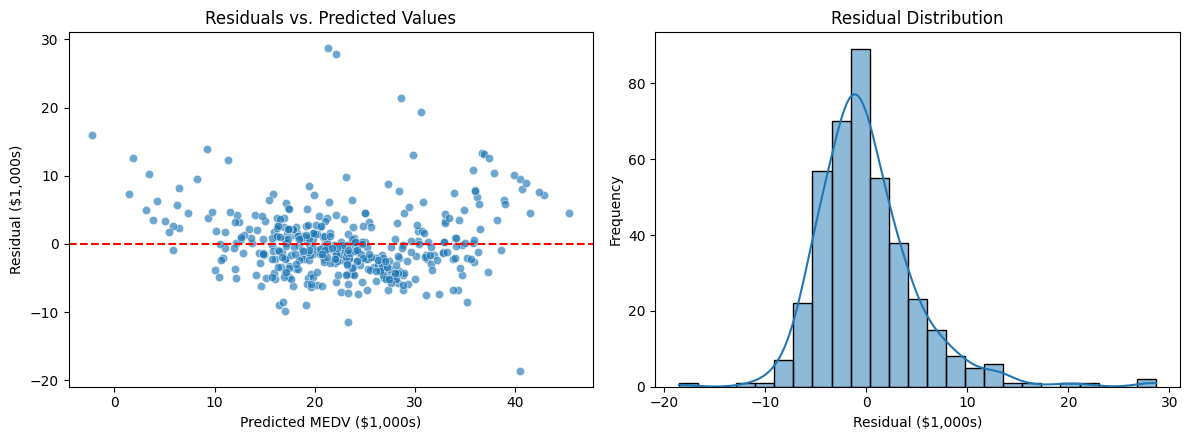

In [15]:
oof_predictions = cross_val_predict(
    LinearRegression(),
    X_train,
    y_train,
    cv=cv
)

residuals = y_train.to_numpy() - oof_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(
    x=oof_predictions,
    y=residuals,
    alpha=0.65,
    ax=axes[0]
)

axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(
    title="Residuals vs. Predicted Values",
    xlabel="Predicted MEDV ($1,000s)",
    ylabel="Residual ($1,000s)"
)

sns.histplot(
    residuals,
    bins=25,
    kde=True,
    ax=axes[1]
)

axes[1].set(
    title="Residual Distribution",
    xlabel="Residual ($1,000s)",
    ylabel="Frequency"
)

plt.tight_layout()
plt.show()


## Model Improvement — Polynomial Features & Ridge

Introduce second-degree polynomial transformations for RM and LSTAT, combined with Ridge regularization, to capture nonlinear relationships.

In [16]:
nonlinear_features = ["RM", "LSTAT"]
remaining_features = [
    feature for feature in X_train.columns
    if feature not in nonlinear_features
]

feature_transformer = ColumnTransformer([
    ("polynomial", Pipeline([
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False))
    ]), nonlinear_features),
    ("remaining", StandardScaler(), remaining_features)
])

polynomial_model = Pipeline([
    ("features", feature_transformer),
    ("regressor", Ridge(alpha=1.0))
])

polynomial_cv_scores = cross_validate(
    polynomial_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MSE": "neg_mean_squared_error",
        "R2": "r2"
    }
)

polynomial_cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MSE": -polynomial_cv_scores["test_MSE"],
    "R2": polynomial_cv_scores["test_R2"]
})

display(polynomial_cv_results.round(4))

print(f"Mean CV MSE: {polynomial_cv_results['MSE'].mean():.4f}")
print(f"Mean CV R²: {polynomial_cv_results['R2'].mean():.4f}")
print(f"CV R² Std: {polynomial_cv_results['R2'].std():.4f}")


,Fold,MSE,R2
0,1,19.9964,0.7188
1,2,14.1717,0.8557
2,3,28.6279,0.6778
3,4,23.1252,0.7838
4,5,11.3076,0.8294


Mean CV MSE: 19.4458
Mean CV R²: 0.7731
CV R² Std: 0.0744


## Model Comparison & Residual Diagnostics

Compare cross-validation performance, select the strongest model, inspect out-of-fold residuals, and report test-set results.

In [17]:
model_comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression",
        "Polynomial + Ridge"
    ],
    "Mean CV MSE": [
        cv_results["MSE"].mean(),
        multiple_cv_results["MSE"].mean(),
        polynomial_cv_results["MSE"].mean()
    ],
    "Mean CV R²": [
        cv_results["R2"].mean(),
        multiple_cv_results["R2"].mean(),
        polynomial_cv_results["R2"].mean()
    ],
    "CV R² Std": [
        cv_results["R2"].std(),
        multiple_cv_results["R2"].std(),
        polynomial_cv_results["R2"].std()
    ]
}).sort_values("Mean CV MSE").reset_index(drop=True)

display(model_comparison.round(4))

final_model = polynomial_model.fit(X_train, y_train)

print("Selected Model: Polynomial + Ridge")
print(f"Training Samples: {len(X_train)}")


,Model,Mean CV MSE,Mean CV R²,CV R² Std
0,Polynomial + Ridge,19.4458,0.7731,0.0744
1,Multiple Linear Regression,25.3022,0.7069,0.0813
2,Simple Linear Regression,43.2784,0.4792,0.1484


Selected Model: Polynomial + Ridge
Training Samples: 404


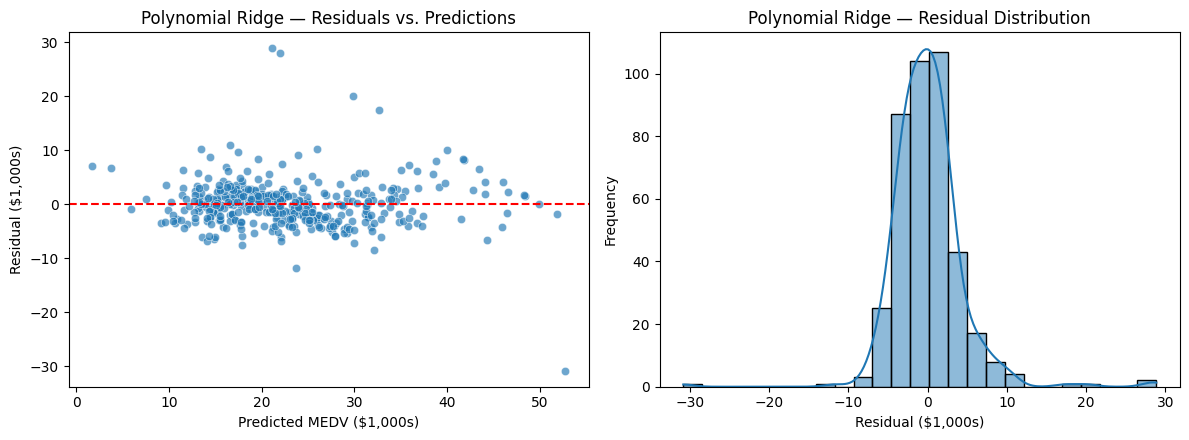

In [18]:
improved_oof_predictions = cross_val_predict(
    polynomial_model,
    X_train,
    y_train,
    cv=cv
)

improved_residuals = y_train.to_numpy() - improved_oof_predictions

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(
    x=improved_oof_predictions,
    y=improved_residuals,
    alpha=0.65,
    ax=axes[0]
)

axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(
    title="Polynomial Ridge — Residuals vs. Predictions",
    xlabel="Predicted MEDV ($1,000s)",
    ylabel="Residual ($1,000s)"
)

sns.histplot(
    improved_residuals,
    bins=25,
    kde=True,
    ax=axes[1]
)

axes[1].set(
    title="Polynomial Ridge — Residual Distribution",
    xlabel="Residual ($1,000s)",
    ylabel="Frequency"
)

plt.tight_layout()
plt.show()


In [19]:
simple_test_predictions = simple_model.predict(X_test[["RM"]])
multiple_test_predictions = multiple_model.predict(X_test)
improved_test_predictions = final_model.predict(X_test)

final_test_comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression",
        "Polynomial + Ridge"
    ],
    "Test MSE": [
        mean_squared_error(y_test, simple_test_predictions),
        mean_squared_error(y_test, multiple_test_predictions),
        mean_squared_error(y_test, improved_test_predictions)
    ],
    "Test RMSE": [
        mean_squared_error(y_test, simple_test_predictions) ** 0.5,
        mean_squared_error(y_test, multiple_test_predictions) ** 0.5,
        mean_squared_error(y_test, improved_test_predictions) ** 0.5
    ],
    "Test R²": [
        r2_score(y_test, simple_test_predictions),
        r2_score(y_test, multiple_test_predictions),
        r2_score(y_test, improved_test_predictions)
    ]
})

display(final_test_comparison.round(4))


,Model,Test MSE,Test RMSE,Test R²
0,Simple Linear Regression,46.1448,6.7930,0.3708
1,Multiple Linear Regression,22.7777,4.7726,0.6894
2,Polynomial + Ridge,13.4531,3.6678,0.8166


## Model Export & Verification

Save the fitted pipeline and cross-validation results, then verify that the exported artifacts can be loaded successfully.

In [20]:
OUTPUT_ROOT = (
    Path("/kaggle/working")
    if Path("/kaggle/working").is_dir()
    else Path("outputs")
)

OUTPUT_DIR = OUTPUT_ROOT / "housing_regression"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "polynomial_ridge_model.joblib"
COMPARISON_PATH = OUTPUT_DIR / "model_comparison.csv"

dump(final_model, MODEL_PATH)
model_comparison.to_csv(COMPARISON_PATH, index=False)

print(f"Output Directory: {OUTPUT_DIR}")

for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{file_path.name} — {file_path.stat().st_size / 1024:.2f} KB")


Output Directory: /kaggle/working/housing_regression
model_comparison.csv — 0.28 KB
polynomial_ridge_model.joblib — 3.42 KB


In [21]:
loaded_model = load(MODEL_PATH)
saved_comparison = pd.read_csv(COMPARISON_PATH)

loaded_predictions = loaded_model.predict(X_test)

pd.testing.assert_series_equal(
    pd.Series(improved_test_predictions),
    pd.Series(loaded_predictions),
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

pd.testing.assert_frame_equal(
    model_comparison,
    saved_comparison,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)

assert loaded_model.n_features_in_ == X_train.shape[1]

print("All saved artifacts passed verification.")
print(f"Verified Model: {type(loaded_model.named_steps['regressor']).__name__}")
print(f"Input Features: {loaded_model.n_features_in_}")
print(f"Verified Predictions: {len(loaded_predictions)}")

All saved artifacts passed verification.
Verified Model: Ridge
Input Features: 12
Verified Predictions: 102


## Final Prediction Visualization

Visualize actual versus predicted home values for the selected Polynomial + Ridge model.


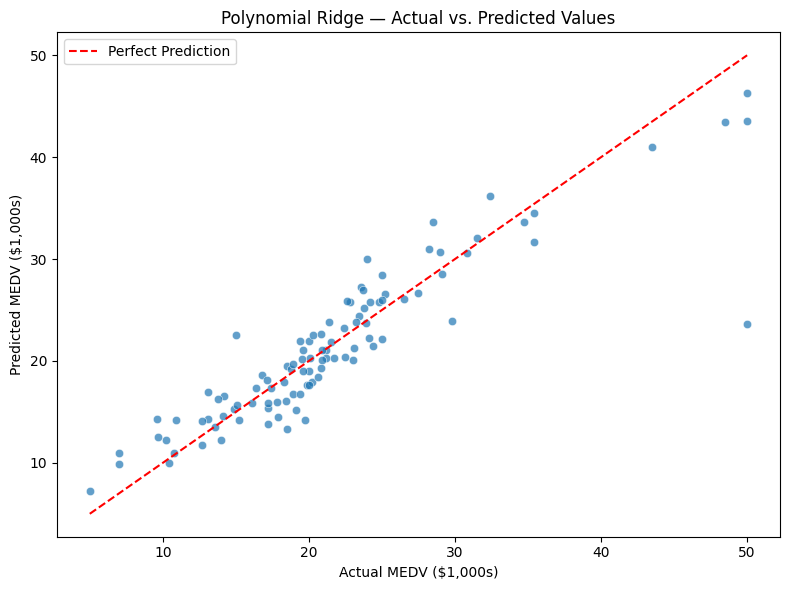

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=improved_test_predictions,
    alpha=0.7,
    ax=ax
)

lower_bound = min(y_test.min(), improved_test_predictions.min())
upper_bound = max(y_test.max(), improved_test_predictions.max())

ax.plot(
    [lower_bound, upper_bound],
    [lower_bound, upper_bound],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

ax.set(
    title="Polynomial Ridge — Actual vs. Predicted Values",
    xlabel="Actual MEDV ($1,000s)",
    ylabel="Predicted MEDV ($1,000s)"
)

ax.legend()
plt.tight_layout()
plt.show()



## Results & Conclusion

### Project Objectives

This project fulfills the Level 1 Linear Regression task by implementing Simple and Multiple Linear Regression, interpreting model coefficients, and evaluating performance using Mean Squared Error (MSE) and R².

A Polynomial + Ridge model was explored separately as an advanced extension.

### Linear Regression Results

| Metric | Simple Linear Regression | Multiple Linear Regression |
|---|---:|---:|
| Mean CV MSE | 43.2784 | 25.3022 |
| Mean CV R² | 0.4792 | 0.7069 |
| Test MSE | 46.1448 | 22.7777 |
| Test RMSE | 6.7930 | 4.7726 |
| Test R² | 0.3708 | 0.6894 |

Multiple Linear Regression substantially improved predictive performance compared with the single-feature RM baseline.

### Coefficient Interpretation

The Multiple Linear Regression model identified a positive coefficient for RM (+4.2401) and negative coefficients for LSTAT (−0.5378) and PTRATIO (−0.8948).

These coefficients describe conditional statistical associations rather than causal effects.

Because predictors use different measurement units, coefficient magnitudes should not be directly compared as measures of feature importance.

Multicollinearity was also observed, particularly between RAD and TAX (correlation = 0.9125). Their VIF values of 7.62 and 8.93 indicate that individual coefficient estimates may be unstable.

### Advanced Extension: Polynomial + Ridge

Exploratory analysis identified RM (r = +0.7107) and LSTAT (r = −0.7364) as the predictors with the strongest positive and negative linear correlations with MEDV.

Their observed relationships motivated the exploration of second-degree polynomial features combined with Ridge regularization.

The extension used a fixed alpha value of 1.0 without hyperparameter tuning.

| Metric | Polynomial + Ridge |
|---|---:|
| Mean CV MSE | 19.4458 |
| Mean CV R² | 0.7731 |
| CV R² Std | 0.0744 |
| Test MSE | 13.4531 |
| Test RMSE | 3.6678 |
| Test R² | 0.8166 |

Polynomial + Ridge achieved the strongest cross-validation performance among the three evaluated approaches.

Its average cross-validation R² was approximately 0.77, while the observed test R² was higher at 0.8166. The difference may reflect variability associated with the particular test split of 102 samples and should not be interpreted as a guaranteed level of performance.

The extension demonstrates the potential benefits of nonlinear feature transformations and regularization. However, it does not replace the primary Linear Regression analysis required for this task.

### Model Diagnostics

Residual analysis showed that the improved model generally produced smaller prediction errors, although outliers and uneven residual dispersion remained.

The model pipeline and cross-validation comparison were exported successfully. The saved pipeline was reloaded and its predictions were verified.

### Limitations

- The Boston Housing dataset is historical and does not represent current housing markets.
- MEDV is capped at 50 ($1,000s), limiting the representation of high-value properties.
- The race-derived feature B was excluded, but other socioeconomic variables may still raise fairness concerns.
- Substantial multicollinearity affects the interpretation of some Multiple Linear Regression coefficients.
- The Ridge regularization strength was not tuned.
- The original test set was examined before the polynomial extension was developed. Although subsequent model selection used training-set cross-validation, the later test comparison cannot be considered completely independent of the overall development process.
- The results come from a single train/test split and should not be generalized without further validation.
The test set was initially examined before the polynomial extension was developed. The improved model was subsequently selected using training-set cross-validation, but the final test comparison should not be treated as a fully independent evaluation of the overall development process.


### Final Conclusion

This project successfully implemented the core requirements of the Codveda Technologies Level 1 Linear Regression task.

Simple Linear Regression established an interpretable baseline, while Multiple Linear Regression improved predictive performance by incorporating additional housing characteristics.

Coefficient interpretation, cross-validation, residual analysis, and multicollinearity diagnostics provided a deeper understanding of model behavior and limitations.

As an optional extension, Polynomial + Ridge achieved stronger cross-validation performance, demonstrating how nonlinear feature engineering and regularization can improve regression models.

The project concludes with reproducible model artifacts, verified outputs, and transparent documentation of the evaluation methodology.
